<a href="https://colab.research.google.com/github/2010626140/pIC50-calculation/blob/main/Ruhul_Final_BCL2_ML_Pipelines_Reviewer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install packages
%%capture
!pip install chembl_webresource_client rdkit tqdm useful_rdkit_utils scikit-posthocs chembl_downloader
# 1️⃣ Reinstall NumPy (force reinstall)
!pip install --upgrade --force-reinstall numpy

# 2️⃣ Restart the runtime after this command
# In Colab: Runtime -> Restart runtime

In [2]:
# Import necessary libraries
import pandas as pd
from chembl_webresource_client.new_client import new_client
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error
import xgboost as xgb
import numpy as np
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV


from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet,
    BayesianRidge, HuberRegressor, Lars, LassoLars
)

from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor,
    GradientBoostingRegressor, AdaBoostRegressor
)

from sklearn.cross_decomposition import PLSRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor




/usr/local/lib/python3.13/dist-packages/chembl_webresource_client/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version


In [3]:
# ======================================
# 3️⃣ Search target
# ======================================
TARGET_NAME = "BCL2"

target = new_client.target
targets = pd.DataFrame(target.search(TARGET_NAME))

targets[
    ["target_chembl_id", "pref_name", "organism", "target_type"]
]



,target_chembl_id,pref_name,organism,target_type
0,CHEMBL3309111,Apoptosis regulator Bcl-2,Mus musculus,SINGLE PROTEIN
1,CHEMBL4860,Apoptosis regulator Bcl-2,Homo sapiens,SINGLE PROTEIN
2,CHEMBL5169264,BCL2/BCL2L11,Homo sapiens,PROTEIN-PROTEIN INTERACTION
3,CHEMBL5169265,BCL2/BID,Homo sapiens,PROTEIN-PROTEIN INTERACTION
4,CHEMBL5169266,BCL2/BAD,Homo sapiens,PROTEIN-PROTEIN INTERACTION
...,...,...,...,...
61,CHEMBL2567,Protein kinase C alpha type,Mus musculus,SINGLE PROTEIN
62,CHEMBL3604,Protein kinase C gamma type,Rattus norvegicus,SINGLE PROTEIN
63,CHEMBL2093867,Protein kinase C (PKC),Homo sapiens,PROTEIN FAMILY
64,CHEMBL2094266,Protein kinase C (PKC),Rattus norvegicus,PROTEIN FAMILY


In [4]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

targets[["target_chembl_id", "pref_name", "organism", "target_type"]]


,target_chembl_id,pref_name,organism,target_type
0,CHEMBL3309111,Apoptosis regulator Bcl-2,Mus musculus,SINGLE PROTEIN
1,CHEMBL4860,Apoptosis regulator Bcl-2,Homo sapiens,SINGLE PROTEIN
2,CHEMBL5169264,BCL2/BCL2L11,Homo sapiens,PROTEIN-PROTEIN INTERACTION
3,CHEMBL5169265,BCL2/BID,Homo sapiens,PROTEIN-PROTEIN INTERACTION
4,CHEMBL5169266,BCL2/BAD,Homo sapiens,PROTEIN-PROTEIN INTERACTION
5,CHEMBL3885516,Apoptosis regulator Bcl-2/Bcl-2 homologous ant...,Homo sapiens,PROTEIN-PROTEIN INTERACTION
6,CHEMBL4523685,Protein cereblon/Apoptosis regulator Bcl-2,Homo sapiens,PROTEIN-PROTEIN INTERACTION
7,CHEMBL3885513,Apoptosis regulator BAX/Bcl-2,Homo sapiens,PROTEIN-PROTEIN INTERACTION
8,CHEMBL4748224,von Hippel-Lindau disease tumor suppressor/Apo...,Homo sapiens,PROTEIN-PROTEIN INTERACTION
9,CHEMBL3817,Bcl2-associated agonist of cell death,Homo sapiens,SINGLE PROTEIN


In [5]:
# ======================================
# 4️⃣ Manually select target
# ======================================
selected_target = "CHEMBL4860"   # Progesterone receptor (Human)

print("Selected target:", selected_target)


Selected target: CHEMBL4860


In [6]:
# ======================================
# 5️⃣ Fetch IC50 bioactivity
# ======================================
activity = new_client.activity

res = activity.filter(
    target_chembl_id=selected_target,
    standard_type="IC50"
)

df = pd.DataFrame(res)

print("Raw data shape:", df.shape)


Raw data shape: (3106, 47)


In [7]:
# ======================================
# 6️⃣ Keep required columns
# ======================================

df = df[[
    "molecule_chembl_id",
    "canonical_smiles",
    "standard_value",
    "standard_units",
    "standard_relation"
]]

# Keep only IC50 in nM
df = df[df["standard_units"] == "nM"]

# Keep exact values only (=)
df = df[df["standard_relation"] == "="]

# Convert IC50 to numeric
df["standard_value"] = pd.to_numeric(df["standard_value"], errors="coerce")

# Remove invalid values
df = df.dropna()

# Remove extreme outliers (very important)
df = df[(df["standard_value"] > 1) & (df["standard_value"] < 1e7)]

# Remove duplicates
df = df.drop_duplicates("canonical_smiles").reset_index(drop=True)

print("Clean bioactivity shape:", df.shape)

Clean bioactivity shape: (1845, 5)


In [8]:
# ======================================
# 7️⃣ Convert IC50 (nM) to pIC50
# ======================================
df["pIC50"] = -np.log10(df["standard_value"] * 1e-9)

df[["standard_value", "pIC50"]].describe()


,standard_value,pIC50
count,1.845000e+03,1845.000000
mean,3.770782e+03,7.489520
std,1.013482e+05,0.997636
min,1.100000e+00,2.366532
25%,5.900000e+00,7.017729
50%,1.900000e+01,7.721246
75%,9.600000e+01,8.229148
max,4.300000e+06,8.958607


In [9]:
df

,molecule_chembl_id,canonical_smiles,standard_value,standard_units,standard_relation,pIC50
0,CHEMBL337153,O=c1c2ccc(S(=O)(=O)c3ccc4c(=O)n5c6ccccc6nc5c5c...,14000.00,nM,=,4.853872
1,CHEMBL340270,Brc1cccc[n+]1-c1ccc2cc(-[n+]3ccccc3Br)ccc2c1,11700.00,nM,=,4.931814
2,CHEMBL443221,Nc1nc(-c2ccccc2)nc2c1[n+]([O-])c1ccccc1[n+]2[O-],1600.00,nM,=,5.795880
3,CHEMBL135934,O=C1c2cc(Br)ccc2-c2ccc3c4ccc5c6c(ccc(c7ccc1c2c...,7700.00,nM,=,5.113509
4,CHEMBL137135,CCOC(=O)C(C#N)C1c2cc(Br)ccc2OC(N)C1C(=O)OCC,9000.00,nM,=,5.045757
5,CHEMBL334590,Cc1cc(Cl)cc(C(=O)Nc2cc(S(=O)(=O)c3ccc(Cl)cc3)c...,3300.00,nM,=,5.481486
6,CHEMBL344184,COc1ccc2c(c1)CCc1cc(OC)ccc1/[N+]([O-])=[N+]\2[O-],10400.00,nM,=,4.982967
7,CHEMBL540363,Cl.N=C(N)c1ccc(/N=N/c2c(O)ccc3c2[nH]c2ccccc23)cc1,5800.00,nM,=,5.236572
8,CHEMBL137800,COc1ccc2c(c1)C(=O)C1C=C([N+]#N)C=CC1N2.[Cl-],10400.00,nM,=,4.982967
9,CHEMBL436605,CCCC[C@H]1C(=O)O[C@H](C)[C@H](NC(=O)c2cccc(NC=...,2000.00,nM,=,5.698970


In [10]:
df.to_csv('BCL2 Chemble Filtered library.csv', index=False)

In [11]:
# Calculate Lipinski descriptors
def lipinski(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.NumHDonors(mol),
        Descriptors.NumHAcceptors(mol)
    ]

lip_df = pd.DataFrame(
    df["canonical_smiles"].apply(lipinski).tolist(),
    columns=["MW", "LogP", "HBD", "HBA"]
)

# Keep ChEMBL ID and SMILES
lip_df = pd.concat([df[["canonical_smiles"]], lip_df], axis=1)
lip_df.head()



,canonical_smiles,MW,LogP,HBD,HBA
0,O=c1c2ccc(S(=O)(=O)c3ccc4c(=O)n5c6ccccc6nc5c5c...,602.631,6.33000,0,6
1,Brc1cccc[n+]1-c1ccc2cc(-[n+]3ccccc3Br)ccc2c1,442.154,4.91820,0,0
2,Nc1nc(-c2ccccc2)nc2c1[n+]([O-])c1ccccc1[n+]2[O-],305.297,1.29900,1,5
3,O=C1c2cc(Br)ccc2-c2ccc3c4ccc5c6c(ccc(c7ccc1c2c...,614.292,9.68500,0,2
4,CCOC(=O)C(C#N)C1c2cc(Br)ccc2OC(N)C1C(=O)OCC,411.252,2.09208,1,7


In [12]:
# 5️⃣ ECFP4 fingerprints
# ==========================
def ecfp4(smiles_list, chembl_ids, n_bits=2048):
    fps = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=n_bits)
        arr = np.zeros((n_bits,), dtype=int)
        AllChem.DataStructs.ConvertToNumpyArray(fp, arr)
        fps.append(arr)
    fp_df = pd.DataFrame(fps, columns=[f'FP_{i}' for i in range(n_bits)])
    # Add ChEMBL ID and SMILES
    fp_df = pd.concat([chembl_ids.reset_index(drop=True), fp_df], axis=1)
    return fp_df

ecfp_df = ecfp4(df['canonical_smiles'], df[['canonical_smiles']])
print("ECFP4 fingerprints shape:", ecfp_df.shape)
ecfp_df.head()

ECFP4 fingerprints shape: (1845, 2049)


canonical_smiles  FP_0  FP_1  FP_2  FP_3  \
0  O=c1c2ccc(S(=O)(=O)c3ccc4c(=O)n5c6ccccc6nc5c5c...     0     0     0     0   
1       Brc1cccc[n+]1-c1ccc2cc(-[n+]3ccccc3Br)ccc2c1     0     0     0     0   
2   Nc1nc(-c2ccccc2)nc2c1[n+]([O-])c1ccccc1[n+]2[O-]     0     0     0     0   
3  O=C1c2cc(Br)ccc2-c2ccc3c4ccc5c6c(ccc(c7ccc1c2c...     0     0     0     0   
4        CCOC(=O)C(C#N)C1c2cc(Br)ccc2OC(N)C1C(=O)OCC     0     1     0     0   

   FP_4  FP_5  FP_6  FP_7  FP_8  FP_9  FP_10  FP_11  FP_12  FP_13  FP_14  \
0     0     0     0     0     0     0      0      0      0      0      0   
1     0     0     0     0     0     0      0      0      0      0      0   
2     0     0     0     0     0     0      0      0      0      0      0   
3     0     0     0     0     0     0      0      0      0      0      0   
4     0     0     0     0     0     0      0      0      0      0      0   

   FP_15  FP_16  FP_17  FP_18  FP_19  FP_20  FP_21  FP_22  FP_23  FP_24  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_25  FP_26  FP_27  FP_28  FP_29  FP_30  FP_31  FP_32  FP_33  FP_34  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_35  FP_36  FP_37  FP_38  FP_39  FP_40  FP_41  FP_42  FP_43  FP_44  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      1      0      0      1      0      0      0      0   

   FP_45  FP_46  FP_47  FP_48  FP_49  FP_50  FP_51  FP_52  FP_53  FP_54  \
0      1      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_55  FP_56  FP_57  FP_58  FP_59  FP_60  FP_61  FP_62  FP_63  FP_64  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_65  FP_66  FP_67  FP_68  FP_69  FP_70  FP_71  FP_72  FP_73  FP_74  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_75  FP_76  FP_77  FP_78  FP_79  FP_80  FP_81  FP_82  FP_83  FP_84  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0  

In [13]:
# 6️⃣ Combine Lipinski + ECFP4 descriptors
# ==========================

# Drop SMILES from both descriptor sets (keep only once later)
X = pd.concat(
    [
        lip_df.drop(columns=['canonical_smiles']),
        ecfp_df.drop(columns=['canonical_smiles'])
    ],
    axis=1
)

# Keep SMILES separately for reference (not for modeling)
X_final_with_id = pd.concat(
    [df[['canonical_smiles']], X],
    axis=1
)

# Target variable
y = df['pIC50']

print("Combined descriptor shape:", X.shape)
print("Target shape:", y.shape)


Combined descriptor shape: (1845, 2052)
Target shape: (1845,)


In [15]:
# Basic info
print("X shape:", X.shape)
print("y shape:", y.shape)

# Preview first few rows
X_final_with_id.head()


X shape: (1845, 2052)
y shape: (1845,)


canonical_smiles       MW     LogP  HBD  \
0  O=c1c2ccc(S(=O)(=O)c3ccc4c(=O)n5c6ccccc6nc5c5c...  602.631  6.33000    0   
1       Brc1cccc[n+]1-c1ccc2cc(-[n+]3ccccc3Br)ccc2c1  442.154  4.91820    0   
2   Nc1nc(-c2ccccc2)nc2c1[n+]([O-])c1ccccc1[n+]2[O-]  305.297  1.29900    1   
3  O=C1c2cc(Br)ccc2-c2ccc3c4ccc5c6c(ccc(c7ccc1c2c...  614.292  9.68500    0   
4        CCOC(=O)C(C#N)C1c2cc(Br)ccc2OC(N)C1C(=O)OCC  411.252  2.09208    1   

   HBA  FP_0  FP_1  FP_2  FP_3  FP_4  FP_5  FP_6  FP_7  FP_8  FP_9  FP_10  \
0    6     0     0     0     0     0     0     0     0     0     0      0   
1    0     0     0     0     0     0     0     0     0     0     0      0   
2    5     0     0     0     0     0     0     0     0     0     0      0   
3    2     0     0     0     0     0     0     0     0     0     0      0   
4    7     0     1     0     0     0     0     0     0     0     0      0   

   FP_11  FP_12  FP_13  FP_14  FP_15  FP_16  FP_17  FP_18  FP_19  FP_20  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_21  FP_22  FP_23  FP_24  FP_25  FP_26  FP_27  FP_28  FP_29  FP_30  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_31  FP_32  FP_33  FP_34  FP_35  FP_36  FP_37  FP_38  FP_39  FP_40  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      1      0      0      1   

   FP_41  FP_42  FP_43  FP_44  FP_45  FP_46  FP_47  FP_48  FP_49  FP_50  \
0      0      0      0      0      1      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_51  FP_52  FP_53  FP_54  FP_55  FP_56  FP_57  FP_58  FP_59  FP_60  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_61  FP_62  FP_63  FP_64  FP_65  FP_66  FP_67  FP_68  FP_69  FP_70  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0      0      0      0      0      0      0      0      0   

   FP_71  FP_72  FP_73  FP_74  FP_75  FP_76  FP_77  FP_78  FP_79  FP_80  \
0      0      0      0      0      0      0      0      0      0      0   
1      0      0      0      0      0      0      0      0      0      0   
2      0      0      0      0      0      0      0      0      0      0   
3      0      0      0      0      0      0      0      0      0      0   
4      0      0  

In [16]:
X_final_with_id.to_csv('BCL2 combined Descriptors.csv', index=False)

In [17]:
# Check missing values
print("Total NaNs in X:", X.isna().sum().sum())

# Check duplicate columns (rare but possible with fingerprints)
print("Duplicate columns:", X.columns.duplicated().sum())


Total NaNs in X: 0
Duplicate columns: 0


In [19]:
final_dataset = pd.concat(
    [
        df[['canonical_smiles']],
        X,
        y.rename('pIC50')
    ],
    axis=1
)

print("Final dataset shape:", final_dataset.shape)

final_dataset.to_csv(
    "BCL2_Lipinski_ECFP4_QSAR_dataset.csv",
    index=False
)

print("Saved: estrogen_Lipinski_ECFP4_QSAR_dataset.csv")


Final dataset shape: (1845, 2054)
Saved: estrogen_Lipinski_ECFP4_QSAR_dataset.csv


In [20]:
# 7️⃣ Train-Test Split
# ==========================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (1476, 2052)
Testing shape: (369, 2052)


In [21]:
# Custom Correlation Filter
# ==========================

from sklearn.base import BaseEstimator, TransformerMixin

class CorrelationFilter(BaseEstimator, TransformerMixin):

    def __init__(self, threshold=0.90):
        self.threshold = threshold

    def fit(self, X, y=None):

        X = np.asarray(X)

        corr_matrix = pd.DataFrame(X).corr().abs()

        upper = corr_matrix.where(
            np.triu(
                np.ones(corr_matrix.shape),
                k=1
            ).astype(bool)
        )

        self.to_drop_ = [
            col for col in upper.columns
            if any(upper[col] > self.threshold)
        ]

        self.keep_indices_ = [
            i for i in range(X.shape[1])
            if i not in self.to_drop_
        ]

        return self

    def transform(self, X):

        X = np.asarray(X)

        return X[:, self.keep_indices_]

In [22]:
# Complete preprocessing Pipeline
# ==========================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold

def create_pipeline(model):

    return Pipeline([

        ('imputer',
         SimpleImputer(strategy='median')),

        ('variance',
         VarianceThreshold(threshold=0.01)),

        ('correlation',
         CorrelationFilter(threshold=0.90)),

        ('model', model)

    ])

In [25]:
# Fit preprocessing steps using training data only

preprocessor = Pipeline([

    ('imputer', SimpleImputer(strategy='median')),

    ('variance', VarianceThreshold(threshold=0.01)),

    ('correlation', CorrelationFilter(threshold=0.90))

])

X_train_processed = preprocessor.fit_transform(X_train)

# Extract retained feature names

variance_mask = preprocessor.named_steps['variance'].get_support()

features_after_variance = X_train.columns[variance_mask]

correlation_indices = preprocessor.named_steps[
    'correlation'
].keep_indices_

retained_features = features_after_variance[correlation_indices]

# Display results

print("Original number of descriptors:", X_train.shape[1])

print("After imputation:", X_train.shape[1])

print("After variance filtering:", len(features_after_variance))

print("After correlation filtering:", len(retained_features))

print("\nFinal retained descriptors:")

print(retained_features.tolist())

Original number of descriptors: 2052
After imputation: 2052
After variance filtering: 715
After correlation filtering: 565

Final retained descriptors:
['MW', 'LogP', 'HBD', 'FP_1', 'FP_2', 'FP_4', 'FP_5', 'FP_8', 'FP_10', 'FP_11', 'FP_12', 'FP_13', 'FP_14', 'FP_20', 'FP_21', 'FP_24', 'FP_26', 'FP_27', 'FP_29', 'FP_32', 'FP_34', 'FP_41', 'FP_43', 'FP_45', 'FP_49', 'FP_53', 'FP_54', 'FP_62', 'FP_67', 'FP_73', 'FP_74', 'FP_79', 'FP_80', 'FP_81', 'FP_82', 'FP_90', 'FP_91', 'FP_92', 'FP_94', 'FP_99', 'FP_100', 'FP_102', 'FP_104', 'FP_108', 'FP_114', 'FP_116', 'FP_117', 'FP_119', 'FP_121', 'FP_124', 'FP_128', 'FP_140', 'FP_142', 'FP_144', 'FP_145', 'FP_147', 'FP_156', 'FP_157', 'FP_162', 'FP_163', 'FP_164', 'FP_165', 'FP_178', 'FP_179', 'FP_180', 'FP_191', 'FP_192', 'FP_193', 'FP_194', 'FP_197', 'FP_198', 'FP_200', 'FP_202', 'FP_203', 'FP_207', 'FP_214', 'FP_216', 'FP_218', 'FP_222', 'FP_227', 'FP_231', 'FP_233', 'FP_235', 'FP_237', 'FP_238', 'FP_242', 'FP_244', 'FP_248', 'FP_249', 'FP_251'

In [30]:
import joblib
import os
import pandas as pd
from xgboost import XGBRegressor

# Reconstruct the optimized pipeline from the known best parameters
if 'best_pipeline' not in locals() and 'best_pipeline' not in globals():
    if os.path.exists('final_selected_model.pkl'):
        print("Loading 'best_pipeline' from saved file...")
        best_pipeline = joblib.load('final_selected_model.pkl')
    else:
        print("Reconstructing and fitting 'best_pipeline' using the optimized hyperparameters...")
        # Define model with best parameters found during search
        optimized_model = XGBRegressor(
            subsample=0.8,
            n_estimators=500,
            max_depth=7,
            learning_rate=0.05,
            colsample_bytree=0.9,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
        # Re-create pipeline
        best_pipeline = create_pipeline(optimized_model)

        # Fit pipeline on training data
        best_pipeline.fit(X_train, y_train)

        # Save it to disk for future steps
        joblib.dump(best_pipeline, 'final_selected_model.pkl')
        print("Optimized model pipeline successfully fitted and saved as 'final_selected_model.pkl'.")
else:
    print("Using 'best_pipeline' already loaded in memory.")

# 2. Transform the training set using the fitted preprocessing steps
X_train_processed = best_pipeline[:-1].transform(X_train)

# 3. Identify features retained after variance filtering
variance_mask = best_pipeline.named_steps['variance'].get_support()
features_after_variance = X_train.columns[variance_mask]

# 4. Identify features retained after correlation filtering
correlation_indices = best_pipeline.named_steps['correlation'].keep_indices_
retained_features = features_after_variance[correlation_indices]

# 5. Create a DataFrame containing the processed training descriptors
X_train_selected = pd.DataFrame(
    X_train_processed,
    columns=retained_features,
    index=X_train.index
)

# 6. Add the corresponding canonical SMILES
training_descriptor_table = pd.concat(
    [
        df.loc[X_train.index, ['canonical_smiles']],
        X_train_selected
    ],
    axis=1
)

# 7. Display the final table
display(training_descriptor_table.head())

# 8. Export to CSV
training_descriptor_table.to_csv(
    "Training_Set_Final_Selected_Descriptors.csv",
    index=False
)

print("\nNumber of training compounds:", len(training_descriptor_table))
print("Number of retained descriptors:", len(retained_features))
print("Training descriptor table saved successfully.")

Reconstructing and fitting 'best_pipeline' using the optimized hyperparameters...
Optimized model pipeline successfully fitted and saved as 'final_selected_model.pkl'.


,canonical_smiles,MW,LogP,HBD,FP_1,FP_2,FP_4,FP_5,FP_8,FP_10,FP_11,FP_12,FP_13,FP_14,FP_20,FP_21,FP_24,FP_26,FP_27,FP_29,FP_32,FP_34,FP_41,FP_43,FP_45,FP_49,FP_53,FP_54,FP_62,FP_67,FP_73,FP_74,FP_79,FP_80,FP_81,FP_82,FP_90,FP_91,FP_92,FP_94,FP_99,FP_100,FP_102,FP_104,FP_108,FP_114,FP_116,FP_117,FP_119,FP_121,FP_124,FP_128,FP_140,FP_142,FP_144,FP_145,FP_147,FP_156,FP_157,FP_162,FP_163,FP_164,FP_165,FP_178,FP_179,FP_180,FP_191,FP_192,FP_193,FP_194,FP_197,FP_198,FP_200,FP_202,FP_203,FP_207,FP_214,FP_216,FP_218,FP_222,FP_227,FP_231,FP_233,FP_235,FP_237,FP_238,FP_242,FP_244,FP_248,FP_249,FP_251,FP_255,FP_260,FP_267,FP_273,FP_283,FP_284,FP_288,FP_289,FP_290,FP_294,FP_295,FP_296,FP_297,FP_299,FP_303,FP_305,FP_310,FP_313,FP_314,FP_317,FP_318,FP_320,FP_321,FP_322,FP_325,FP_327,FP_328,FP_330,FP_335,FP_338,FP_340,FP_348,FP_351,FP_352,FP_354,FP_361,FP_362,FP_366,FP_371,FP_376,FP_378,FP_380,FP_383,FP_384,FP_389,FP_390,FP_392,FP_394,FP_407,FP_410,FP_422,FP_425,FP_440,FP_441,FP_446,FP_456,FP_459,FP_462,FP_464,FP_472,FP_474,FP_478,FP_482,FP_490,FP_492,FP_493,FP_496,FP_501,FP_507,FP_517,FP_519,FP_522,FP_523,FP_526,FP_529,FP_531,FP_533,FP_545,FP_552,FP_555,FP_556,FP_558,FP_561,FP_562,FP_564,FP_573,FP_574,FP_575,FP_581,FP_582,FP_585,FP_586,FP_590,FP_591,FP_592,FP_597,FP_598,FP_600,FP_602,FP_611,FP_614,FP_621,FP_624,FP_626,FP_633,FP_634,FP_637,FP_638,FP_650,FP_652,FP_653,FP_656,FP_664,FP_665,FP_666,FP_667,FP_674,FP_675,FP_679,FP_680,FP_682,FP_685,FP_687,FP_688,FP_690,FP_692,FP_693,FP_694,FP_695,FP_699,FP_700,FP_708,FP_709,FP_710,FP_718,FP_724,FP_725,FP_726,FP_728,FP_732,FP_734,FP_736,FP_738,FP_739,FP_741,FP_743,FP_745,FP_752,FP_759,FP_765,FP_766,FP_772,FP_781,FP_784,FP_785,FP_786,FP_787,FP_798,FP_799,FP_800,FP_802,FP_803,FP_807,FP_808,FP_809,FP_811,FP_812,FP_820,FP_823,FP_832,FP_833,FP_837,FP_838,FP_841,FP_842,FP_843,FP_845,FP_847,FP_849,FP_855,FP_861,FP_867,FP_868,FP_871,FP_872,FP_875,FP_878,FP_879,FP_880,FP_881,FP_883,FP_886,FP_889,FP_890,FP_895,FP_896,FP_898,FP_899,FP_909,FP_912,FP_913,FP_920,FP_926,FP_927,FP_935,FP_950,FP_955,FP_974,FP_978,FP_980,FP_981,FP_984,FP_989,FP_1003,FP_1009,FP_1017,FP_1019,FP_1028,FP_1033,FP_1034,FP_1039,FP_1040,FP_1045,FP_1049,FP_1051,FP_1053,FP_1057,FP_1060,FP_1063,FP_1065,FP_1066,FP_1070,FP_1071,FP_1075,FP_1076,FP_1077,FP_1083,FP_1084,FP_1087,FP_1088,FP_1092,FP_1097,FP_1101,FP_1104,FP_1105,FP_1108,FP_1110,FP_1111,FP_1118,FP_1135,FP_1136,FP_1138,FP_1141,FP_1145,FP_1147,FP_1152,FP_1154,FP_1163,FP_1168,FP_1171,FP_1182,FP_1185,FP_1187,FP_1195,FP_1199,FP_1205,FP_1223,FP_1224,FP_1231,FP_1233,FP_1238,FP_1243,FP_1244,FP_1252,FP_1253,FP_1255,FP_1257,FP_1260,FP_1261,FP_1267,FP_1269,FP_1270,FP_1274,FP_1279,FP_1281,FP_1285,FP_1287,FP_1290,FP_1292,FP_1295,FP_1298,FP_1307,FP_1308,FP_1309,FP_1312,FP_1314,FP_1317,FP_1321,FP_1325,FP_1327,FP_1332,FP_1333,FP_1343,FP_1349,FP_1357,FP_1365,FP_1366,FP_1367,FP_1370,FP_1372,FP_1374,FP_1377,FP_1384,FP_1385,FP_1391,FP_1393,FP_1395,FP_1399,FP_1402,FP_1405,FP_1409,FP_1410,FP_1417,FP_1424,FP_1430,FP_1437,FP_1439,FP_1440,FP_1441,FP_1446,FP_1447,FP_1452,FP_1453,FP_1455,FP_1457,FP_1460,FP_1479,FP_1480,FP_1482,FP_1487,FP_1490,FP_1501,FP_1508,FP_1516,FP_1529,FP_1535,FP_1536,FP_1545,FP_1547,FP_1564,FP_1572,FP_1573,FP_1574,FP_1575,FP_1576,FP_1579,FP_1581,FP_1589,FP_1594,FP_1597,FP_1603,FP_1607,FP_1613,FP_1616,FP_1617,FP_1624,FP_1647,FP_1649,FP_1652,FP_1653,FP_1662,FP_1663,FP_1665,FP_1670,FP_1671,FP_1676,FP_1685,FP_1687,FP_1690,FP_1691,FP_1693,FP_1696,FP_1697,FP_1700,FP_1715,FP_1716,FP_1722,FP_1727,FP_1729,FP_1733,FP_1734,FP_1736,FP_1737,FP_1738,FP_1741,FP_1744,FP_1745,FP_1747,FP_1750,FP_1754,FP_1756,FP_1758,FP_1760,FP_1762,FP_1765,FP_1766,FP_1769,FP_1780,FP_1783,FP_1785,FP_1786,FP_1791,FP_1799,FP_1800,FP_1803,FP_1810,FP_1816,FP_1823,FP_1825,FP_1838,FP_1839,FP_1840,FP_1844,FP_1847,FP_1852,FP_1854,FP_1855,FP_1859,FP_1862,FP_1863,FP_1866,FP_1876,FP_1879,FP_1897,FP_1911,FP_1914,FP_1915,FP_1916,FP_1917,FP_1920,FP_1921,FP_1922,FP_1923,FP_1926,FP_1928,FP_1933,FP_1937,FP_1939,FP_1942,FP_1945,FP_1950,FP_1951,


Number of training compounds: 1476
Number of retained descriptors: 565
Training descriptor table saved successfully.


In [31]:
# Transform testing data using the already-fitted training pipeline
X_test_processed = best_pipeline[:-1].transform(X_test)

# Get retained feature names
variance_mask = best_pipeline.named_steps['variance'].get_support()
features_after_variance = X.columns[variance_mask]

correlation_indices = best_pipeline.named_steps['correlation'].keep_indices_
retained_features = features_after_variance[correlation_indices]

# Convert processed testing data into a DataFrame
X_test_selected = pd.DataFrame(
    X_test_processed,
    columns=retained_features,
    index=X_test.index
)

# Add canonical SMILES
test_descriptor_table = pd.concat(
    [
        df.loc[X_test.index, ['canonical_smiles']],
        X_test_selected
    ],
    axis=1
)

# Display the table
display(test_descriptor_table)

# Export
test_descriptor_table.to_csv(
    "Final_Selected_Descriptors_Testing.csv",
    index=False
)



,canonical_smiles,MW,LogP,HBD,FP_1,FP_2,FP_4,FP_5,FP_8,FP_10,FP_11,FP_12,FP_13,FP_14,FP_20,FP_21,FP_24,FP_26,FP_27,FP_29,FP_32,FP_34,FP_41,FP_43,FP_45,FP_49,FP_53,FP_54,FP_62,FP_67,FP_73,FP_74,FP_79,FP_80,FP_81,FP_82,FP_90,FP_91,FP_92,FP_94,FP_99,FP_100,FP_102,FP_104,FP_108,FP_114,FP_116,FP_117,FP_119,FP_121,FP_124,FP_128,FP_140,FP_142,FP_144,FP_145,FP_147,FP_156,FP_157,FP_162,FP_163,FP_164,FP_165,FP_178,FP_179,FP_180,FP_191,FP_192,FP_193,FP_194,FP_197,FP_198,FP_200,FP_202,FP_203,FP_207,FP_214,FP_216,FP_218,FP_222,FP_227,FP_231,FP_233,FP_235,FP_237,FP_238,FP_242,FP_244,FP_248,FP_249,FP_251,FP_255,FP_260,FP_267,FP_273,FP_283,FP_284,FP_288,FP_289,FP_290,FP_294,FP_295,FP_296,FP_297,FP_299,FP_303,FP_305,FP_310,FP_313,FP_314,FP_317,FP_318,FP_320,FP_321,FP_322,FP_325,FP_327,FP_328,FP_330,FP_335,FP_338,FP_340,FP_348,FP_351,FP_352,FP_354,FP_361,FP_362,FP_366,FP_371,FP_376,FP_378,FP_380,FP_383,FP_384,FP_389,FP_390,FP_392,FP_394,FP_407,FP_410,FP_422,FP_425,FP_440,FP_441,FP_446,FP_456,FP_459,FP_462,FP_464,FP_472,FP_474,FP_478,FP_482,FP_490,FP_492,FP_493,FP_496,FP_501,FP_507,FP_517,FP_519,FP_522,FP_523,FP_526,FP_529,FP_531,FP_533,FP_545,FP_552,FP_555,FP_556,FP_558,FP_561,FP_562,FP_564,FP_573,FP_574,FP_575,FP_581,FP_582,FP_585,FP_586,FP_590,FP_591,FP_592,FP_597,FP_598,FP_600,FP_602,FP_611,FP_614,FP_621,FP_624,FP_626,FP_633,FP_634,FP_637,FP_638,FP_650,FP_652,FP_653,FP_656,FP_664,FP_665,FP_666,FP_667,FP_674,FP_675,FP_679,FP_680,FP_682,FP_685,FP_687,FP_688,FP_690,FP_692,FP_693,FP_694,FP_695,FP_699,FP_700,FP_708,FP_709,FP_710,FP_718,FP_724,FP_725,FP_726,FP_728,FP_732,FP_734,FP_736,FP_738,FP_739,FP_741,FP_743,FP_745,FP_752,FP_759,FP_765,FP_766,FP_772,FP_781,FP_784,FP_785,FP_786,FP_787,FP_798,FP_799,FP_800,FP_802,FP_803,FP_807,FP_808,FP_809,FP_811,FP_812,FP_820,FP_823,FP_832,FP_833,FP_837,FP_838,FP_841,FP_842,FP_843,FP_845,FP_847,FP_849,FP_855,FP_861,FP_867,FP_868,FP_871,FP_872,FP_875,FP_878,FP_879,FP_880,FP_881,FP_883,FP_886,FP_889,FP_890,FP_895,FP_896,FP_898,FP_899,FP_909,FP_912,FP_913,FP_920,FP_926,FP_927,FP_935,FP_950,FP_955,FP_974,FP_978,FP_980,FP_981,FP_984,FP_989,FP_1003,FP_1009,FP_1017,FP_1019,FP_1028,FP_1033,FP_1034,FP_1039,FP_1040,FP_1045,FP_1049,FP_1051,FP_1053,FP_1057,FP_1060,FP_1063,FP_1065,FP_1066,FP_1070,FP_1071,FP_1075,FP_1076,FP_1077,FP_1083,FP_1084,FP_1087,FP_1088,FP_1092,FP_1097,FP_1101,FP_1104,FP_1105,FP_1108,FP_1110,FP_1111,FP_1118,FP_1135,FP_1136,FP_1138,FP_1141,FP_1145,FP_1147,FP_1152,FP_1154,FP_1163,FP_1168,FP_1171,FP_1182,FP_1185,FP_1187,FP_1195,FP_1199,FP_1205,FP_1223,FP_1224,FP_1231,FP_1233,FP_1238,FP_1243,FP_1244,FP_1252,FP_1253,FP_1255,FP_1257,FP_1260,FP_1261,FP_1267,FP_1269,FP_1270,FP_1274,FP_1279,FP_1281,FP_1285,FP_1287,FP_1290,FP_1292,FP_1295,FP_1298,FP_1307,FP_1308,FP_1309,FP_1312,FP_1314,FP_1317,FP_1321,FP_1325,FP_1327,FP_1332,FP_1333,FP_1343,FP_1349,FP_1357,FP_1365,FP_1366,FP_1367,FP_1370,FP_1372,FP_1374,FP_1377,FP_1384,FP_1385,FP_1391,FP_1393,FP_1395,FP_1399,FP_1402,FP_1405,FP_1409,FP_1410,FP_1417,FP_1424,FP_1430,FP_1437,FP_1439,FP_1440,FP_1441,FP_1446,FP_1447,FP_1452,FP_1453,FP_1455,FP_1457,FP_1460,FP_1479,FP_1480,FP_1482,FP_1487,FP_1490,FP_1501,FP_1508,FP_1516,FP_1529,FP_1535,FP_1536,FP_1545,FP_1547,FP_1564,FP_1572,FP_1573,FP_1574,FP_1575,FP_1576,FP_1579,FP_1581,FP_1589,FP_1594,FP_1597,FP_1603,FP_1607,FP_1613,FP_1616,FP_1617,FP_1624,FP_1647,FP_1649,FP_1652,FP_1653,FP_1662,FP_1663,FP_1665,FP_1670,FP_1671,FP_1676,FP_1685,FP_1687,FP_1690,FP_1691,FP_1693,FP_1696,FP_1697,FP_1700,FP_1715,FP_1716,FP_1722,FP_1727,FP_1729,FP_1733,FP_1734,FP_1736,FP_1737,FP_1738,FP_1741,FP_1744,FP_1745,FP_1747,FP_1750,FP_1754,FP_1756,FP_1758,FP_1760,FP_1762,FP_1765,FP_1766,FP_1769,FP_1780,FP_1783,FP_1785,FP_1786,FP_1791,FP_1799,FP_1800,FP_1803,FP_1810,FP_1816,FP_1823,FP_1825,FP_1838,FP_1839,FP_1840,FP_1844,FP_1847,FP_1852,FP_1854,FP_1855,FP_1859,FP_1862,FP_1863,FP_1866,FP_1876,FP_1879,FP_1897,FP_1911,FP_1914,FP_1915,FP_1916,FP_1917,FP_1920,FP_1921,FP_1922,FP_1923,FP_1926,FP_1928,FP_1933,FP_1937,FP_1939,FP_1942,FP_1945,FP_1950,FP_1951,

In [32]:
models = {

    # 1–4 Linear models
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001),
    "ElasticNet": ElasticNet(alpha=0.001, l1_ratio=0.5),

    # 5–8 Robust / probabilistic
    "BayesianRidge": BayesianRidge(),
    "Huber": HuberRegressor(),
    "LARS": Lars(),
    "LassoLARS": LassoLars(alpha=0.001),

    # 9–11 Kernel / instance based
    "SVR_RBF": SVR(kernel="rbf", C=10, gamma="scale"),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "KernelRidge": KernelRidge(alpha=1.0, kernel="rbf"),

    # 12–14 Tree based
    "DecisionTree": DecisionTreeRegressor(random_state=42),
    "RandomForest": RandomForestRegressor(
        n_estimators=500, random_state=42, n_jobs=-1
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=500, random_state=42, n_jobs=-1
    ),

    # 15–16 Boosting
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),

    # 17 PLS (QSAR classic)
    "PLS": PLSRegression(n_components=10),

    # 18 Neural Network
    "MLP": MLPRegressor(
        hidden_layer_sizes=(100, 50),
        max_iter=1000,
        random_state=42
    ),

    # 19 Advanced boosting
    "XGBoost": XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}


In [54]:
# Model Comparison Using Cross-Validation
# ========================================

from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    print(f"Evaluating: {name}")

    pipeline = create_pipeline(model)

    scores = cross_validate(

        pipeline,

        X_train,

        y_train,

        cv=cv,

        scoring={
            'R2': 'r2',
            'RMSE': 'neg_root_mean_squared_error',
            'MAE': 'neg_mean_absolute_error'
        },

        n_jobs=-1

    )

    results.append({

        'Model': name,

        'Mean_CV_R2': scores['test_R2'].mean(),

        'SD_CV_R2': scores['test_R2'].std(),

        'Mean_CV_RMSE': -scores['test_RMSE'].mean(),

        'Mean_CV_MAE': -scores['test_MAE'].mean()

    })


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Mean_CV_R2',
    ascending=False
)

results_df

Evaluating: Linear
Evaluating: Ridge
Evaluating: Lasso
Evaluating: ElasticNet
Evaluating: BayesianRidge
Evaluating: Huber
Evaluating: LARS
Evaluating: LassoLARS
Evaluating: SVR_RBF
Evaluating: KNN
Evaluating: KernelRidge
Evaluating: DecisionTree
Evaluating: RandomForest
Evaluating: ExtraTrees
Evaluating: GradientBoosting
Evaluating: AdaBoost
Evaluating: PLS
Evaluating: MLP
Evaluating: XGBoost


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,Model,Mean_CV_R2,SD_CV_R2,Mean_CV_RMSE,Mean_CV_MAE
18,XGBoost,0.709836,0.056981,0.533185,0.373136
12,RandomForest,0.705037,0.057746,0.538268,0.383092
4,BayesianRidge,0.678885,0.059772,0.561927,0.412471
2,Lasso,0.677063,0.065045,0.562899,0.413302
7,LassoLARS,0.677063,0.065048,0.562900,0.413302
3,ElasticNet,0.672446,0.067706,0.566599,0.414163
14,GradientBoosting,0.671457,0.066315,0.568101,0.422911
16,PLS,0.641709,0.052447,0.594724,0.441286
1,Ridge,0.622597,0.073012,0.608545,0.444624
13,ExtraTrees,0.580602,0.075827,0.641715,0.442382


In [55]:
# Select best algorithm based on CV performance
# ==============================================

best_model_name = results_df.iloc[0]['Model']

best_model = models[best_model_name]

print("Best model:", best_model_name)

print(
    "Best CV R2:",
    results_df.iloc[0]['Mean_CV_R2']
)

Best model: XGBoost
Best CV R2: 0.7098362625173664


In [56]:
# XGBoost hyperparameter distribution

param_dist = {

    'model__n_estimators': [
        200, 300, 400, 500, 600
    ],

    'model__max_depth': [
        4, 5, 6, 7, 8
    ],

    'model__learning_rate': [
        0.01, 0.03, 0.05, 0.07, 0.1
    ],

    'model__subsample': [
        0.7, 0.8, 0.9, 1.0
    ],

    'model__colsample_bytree': [
        0.7, 0.8, 0.9, 1.0
    ]

}

In [57]:
best_pipeline = create_pipeline(best_model)

In [58]:
random_search = RandomizedSearchCV(

    estimator=best_pipeline,

    param_distributions=param_dist,

    n_iter=50,

    cv=5,

    scoring='r2',

    verbose=2,

    random_state=42,

    n_jobs=-1

)

In [59]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('imputer',
                                              SimpleImputer(strategy='median')),
                                             ('variance',
                                              VarianceThreshold(threshold=0.01)),
                                             ('correlation',
                                              CorrelationFilter()),
                                             ('model',
                                              XGBRegressor(base_score=None,
                                                           booster=None,
                                                           callbacks=None,
                                                           colsample_bylevel=None,
                                                           colsample_bynode=None,
                                                           colsample_bytree=0.8,
                                                           device=None,
                                                           early_stopping_rounds=None,
                                                           e...
                                                           multi_strategy=None,
                                                           n_estimators=500,
                                                           n_jobs=-1,
                                                           num_parallel_tree=None, ...))]),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'model__colsample_bytree': [0.7, 0.8,
                                                                    0.9, 1.0],
                                        'model__learning_rate': [0.01, 0.03,
                                                                 0.05, 0.07,
                                                                 0.1],
                                        'model__max_depth': [4, 5, 6, 7, 8],
                                        'model__n_estimators': [200, 300, 400,
                                                                500, 600],
                                        'model__subsample': [0.7, 0.8, 0.9,
                                                             1.0]},
                   random_state=42, scoring='r2', verbose=2)

In [60]:
print("Best parameters:", random_search.best_params_)

print("Best CV R2:", random_search.best_score_)

Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 500, 'model__max_depth': 7, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.8}
Best CV R2: 0.7116040132028018


In [61]:
best_pipeline = random_search.best_estimator_

In [62]:
# Independent Test Evaluation
# ==========================

y_pred = best_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Final Model:", best_model_name)

print(f"MAE: {mae:.4f}")

print(f"RMSE: {rmse:.4f}")

print(f"R2: {r2:.4f}")

Final Model: XGBoost
MAE: 0.3793
RMSE: 0.5276
R2: 0.7075


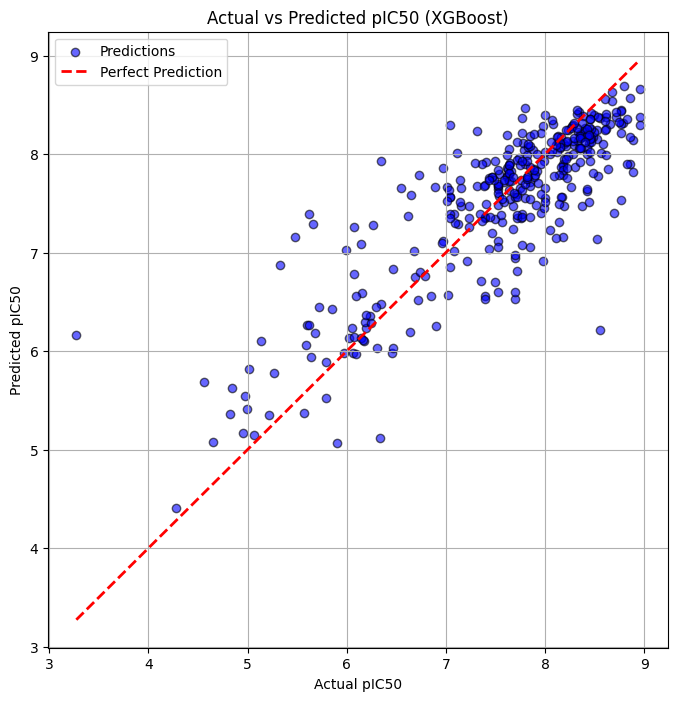

In [63]:
# ==========================
# 1️⃣ Actual vs Predicted Scatter Plot
# ==========================
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))
plt.scatter(y_test, y_pred, alpha=0.6, color='blue', edgecolors='k', label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2, label='Perfect Prediction')
plt.xlabel("Actual pIC50")
plt.ylabel("Predicted pIC50")
plt.title("Actual vs Predicted pIC50 (XGBoost)")
plt.legend()
plt.grid(True)
plt.show()




In [64]:
# Extract selected features from preprocessing pipeline

variance_mask = best_pipeline.named_steps[
    'variance'
].get_support()

features_after_variance = X.columns[variance_mask]

correlation_indices = best_pipeline.named_steps[
    'correlation'
].keep_indices_

selected_features = features_after_variance[
    correlation_indices
]

final_estimator = best_pipeline.named_steps['model']

if hasattr(final_estimator, 'feature_importances_'):

    importances = final_estimator.feature_importances_

    feature_names = selected_features

    importance_df = pd.DataFrame({

        'Feature': feature_names,

        'Importance': importances

    }).sort_values(
        by='Importance',
        ascending=False
    )

    print(importance_df.head(20))

     Feature  Importance
427  FP_1480    0.061354
524  FP_1911    0.031753
552  FP_1991    0.030110
306  FP_1019    0.021211
383  FP_1309    0.020234
514  FP_1852    0.016371
430  FP_1490    0.011524
381  FP_1307    0.011098
292   FP_926    0.009508
62    FP_178    0.009344
373  FP_1279    0.009326
298   FP_978    0.007770
321  FP_1070    0.007361
100   FP_295    0.007337
294   FP_935    0.007268
276   FP_878    0.006849
70    FP_198    0.006411
239   FP_765    0.006233
259   FP_832    0.006198
126   FP_362    0.006186


In [65]:
# Save Independent Test Predictions
# ==========================

predictions_df = pd.DataFrame({

    "Actual_pIC50": y_test,

    "Predicted_pIC50": y_pred

})

predictions_df.to_csv(
    "final_model_test_predictions.csv",
    index=False
)

print("Independent test predictions saved successfully!")

Independent test predictions saved successfully!


In [66]:
import joblib

joblib.dump(
    best_pipeline,
    'final_selected_model.pkl'
)

print("Complete model pipeline saved!")

Complete model pipeline saved!


In [67]:
best_pipeline = joblib.load(
    'final_selected_model.pkl'
)

print("Complete model pipeline loaded!")

Complete model pipeline loaded!


In [68]:
# Load complete optimized ML pipeline
import joblib

best_pipeline = joblib.load("final_selected_model.pkl")

print("Complete ML pipeline loaded successfully!")

Complete ML pipeline loaded successfully!


In [69]:
# 2️⃣ Load new ligands CSV
# ==========================
new_ligands = pd.read_csv("ML_SMILES.csv")
print("New ligands loaded:", new_ligands.shape)
new_ligands.head()

New ligands loaded: (28, 1)


,SMILES
0,CCCCCCCCCCCCCCCC(=O)OC
1,CCCCCCCCCCC/C=C\CCCCC(=O)OC
2,CCCCCCOCCCCCC
3,CCC#CCCCCCCCCOC(=O)CCl
4,CCCCCCCCCCCCI


In [73]:
# 3️⃣ Calculate Lipinski descriptors
# ==========================
def lipinski(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return [None, None, None, None]
    return [
        Descriptors.MolWt(mol),
        Descriptors.MolLogP(mol),
        Descriptors.NumHDonors(mol),
        Descriptors.NumHAcceptors(mol)
    ]

# Extract Lipinski descriptors using the correct 'SMILES' column
lip_df_new = pd.DataFrame(
    new_ligands["SMILES"].apply(lipinski).tolist(),
    columns=["MW", "LogP", "HBD", "HBA"]
)

# Add the smiles back as 'canonical_smiles' for downstream compatibility
lip_df_new = pd.concat([
    new_ligands[["SMILES"]].rename(columns={"SMILES": "canonical_smiles"}).reset_index(drop=True),
    lip_df_new
], axis=1)

# Display the preview
lip_df_new.head()

,canonical_smiles,MW,LogP,HBD,HBA
0,CCCCCCCCCCCCCCCC(=O)OC,270.457,5.6407,0,2
1,CCCCCCCCCCC/C=C\CCCCC(=O)OC,296.495,6.1969,0,2
2,CCCCCCOCCCCCC,186.339,4.1636,0,1
3,CCC#CCCCCCCCCOC(=O)CCl,258.789,3.9125,0,2
4,CCCCCCCCCCCCI,296.236,5.3423,0,0


In [76]:
# 4️⃣ Calculate ECFP4 fingerprints
# ==========================
def ecfp4(smiles_list, n_bits=2048):
    fps = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=n_bits)
        arr = np.zeros((n_bits,), dtype=int)
        AllChem.DataStructs.ConvertToNumpyArray(fp, arr)
        fps.append(arr)
    fp_df = pd.DataFrame(fps, columns=[f'FP_{i}' for i in range(n_bits)])
    return fp_df

# Fix KeyError by using the correct 'SMILES' column from new_ligands
ecfp_df_new = ecfp4(new_ligands["SMILES"])

In [77]:
# 5️⃣ Combine Lipinski + ECFP4 descriptors
# ==========================
X_new = pd.concat([lip_df_new.drop(columns=['canonical_smiles']), ecfp_df_new], axis=1)
print("Combined descriptor shape:", X_new.shape)


Combined descriptor shape: (28, 2052)


In [78]:
# 6️⃣ Align New Compound Features with Training Features
# ======================================================

X_new = X_new.reindex(columns=X.columns)

print("New compound descriptor shape:", X_new.shape)
print("Training feature shape:", X.shape)

assert list(X_new.columns) == list(X.columns)

New compound descriptor shape: (28, 2052)
Training feature shape: (1845, 2052)


In [79]:
# 7️⃣ Predict pIC50
# ==========================

y_pred_new = best_pipeline.predict(X_new)

predictions_new = new_ligands.copy()

predictions_new['Predicted_pIC50'] = y_pred_new

predictions_new = predictions_new.sort_values(
    by='Predicted_pIC50',
    ascending=False
)

predictions_new.to_csv(
    'Predicted_pIC50_New_Compounds.csv',
    index=False
)

print(predictions_new.head(10))

                                               SMILES  Predicted_pIC50
13  C1=CC(=C(C(=C1)C(F)(F)F)F)C(=O)OC2=C(C(=CC=C2)...         5.771176
5       CC/C=C\C/C=C\C/C=C\C/C=C\C/C=C\C/C=C\CCC(=O)O         5.614268
9                         CCCCCCCC/C=C\CCCCCCCC(=O)OC         5.486124
1                         CCCCCCCCCCC/C=C\CCCCC(=O)OC         5.486124
17                      CCC(C)CCCCC(C)CCCC(C)CCCC(C)C         5.456290
4                                       CCCCCCCCCCCCI         5.427752
27                    CCCCCOC(=O)C1CCCCN1C(=O)OCC(C)C         5.390323
0                              CCCCCCCCCCCCCCCC(=O)OC         4.608778
7                       CC1C2=CC=CC=C2C3=CC=CC(=C13)C         4.474070
22                               CCCCCCCCCCCCCC(=O)OC         4.417275
